# 第 4 章 抽样、记分与精度 — 代码实验

对照教材：Dunn & Shultis《Exploring Monte Carlo Methods》Ch.4；Shonkwiler & Mendivil《Explorations in Monte Carlo Methods》Ch.2。

约定：随机种子 2024；所有插图保存到 `docs/mc/images/ch04/`，编号 `out-4-M` 与笔记图注一一对应。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from collections import deque
from pathlib import Path

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
FIGDIR = Path(r"E:/Desktop/深度学习/mynotes/docs/mc/images/ch04")
FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")

rng = np.random.default_rng(2024)   # 全章共用一个随机数流
print("numpy", np.__version__)

numpy 2.4.6


## 实验 1 连续逆 CDF：指数分布（§4.1.1）

$F(x)=1-e^{-\alpha x}$ 解出 $x=-\ln(1-\rho)/\alpha$，$\rho\sim U(0,1)$。取 $\alpha=1$。右图把直方图高度放到半对数坐标——密度若真是 $e^{-x}$，log 高度对 $x$ 应该是一条斜率 $-1$ 的直线，这是对指数性最灵敏的检验。

样本均值 0.9968（理论 1），样本方差 0.9967（理论 1）


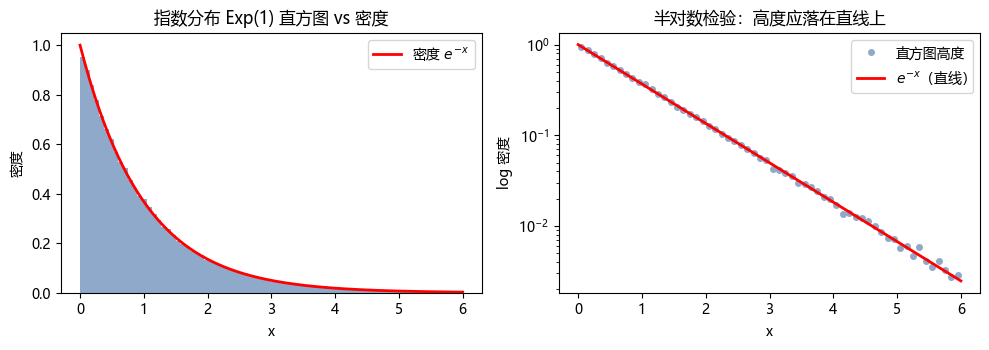

In [2]:
N = 200_000
u = rng.random(N)
X = -np.log1p(-u)          # x = -ln(1-ρ)，α = 1
print(f"样本均值 {X.mean():.4f}（理论 1），样本方差 {X.var():.4f}（理论 1）")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
xx = np.linspace(0, 6, 400)
ax[0].hist(X, bins=80, range=(0, 6), density=True, color="#8ea9c9")
ax[0].plot(xx, np.exp(-xx), "r-", lw=2, label=r"密度 $e^{-x}$")
ax[0].set(title="指数分布 Exp(1) 直方图 vs 密度", xlabel="x", ylabel="密度")
ax[0].legend()
cnts, edges = np.histogram(X, bins=60, range=(0, 6), density=True)
ctr = (edges[:-1] + edges[1:]) / 2
m = cnts > 0
ax[1].semilogy(ctr[m], cnts[m], "o", ms=4, color="#8ea9c9", label="直方图高度")
ax[1].semilogy(xx, np.exp(-xx), "r-", lw=2, label=r"$e^{-x}$（直线）")
ax[1].set(title="半对数检验：高度应落在直线上", xlabel="x", ylabel="log 密度")
ax[1].legend()
fig.tight_layout(); save(fig, "out-4-1.png"); plt.show()

## 实验 2 离散逆 CDF：二项与泊松（§4.1.2）

二项 $b(20,0.25)$：把 20 次 Bernoulli 试验（$U<p$ 记成功）求和。泊松 $Pois(4)$：乘积法——连乘均匀数，第一次低于 $e^{-\lambda t}$ 时数乘积个数（向量化版：累计乘积逐列与阈值比较）。

二项 b(20,0.25): 均值 4.9969（理论 5.0），方差 3.7322（理论 3.75）
泊松 Pois(4):   均值 4.0020（理论 4），方差 3.9958（理论 4）


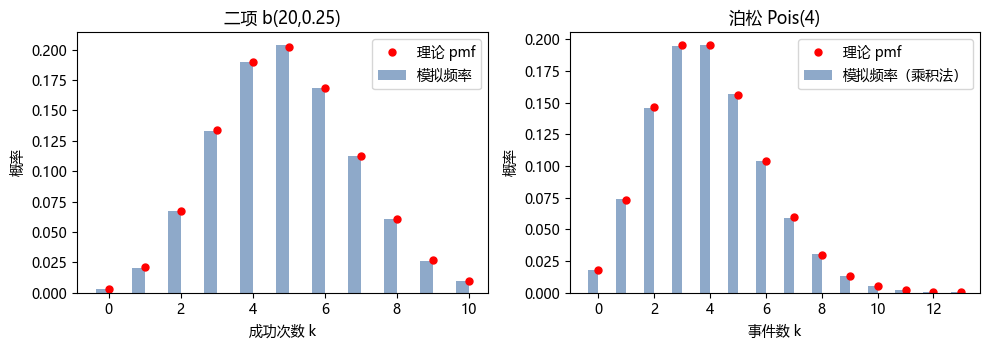

In [3]:
N, n, p = 200_000, 20, 0.25
Xb = (rng.random((N, n)) < p).sum(axis=1)          # 二项 = n 次 Bernoulli 之和

lam = 4.0
L = np.exp(-lam)
Xp = (np.cumprod(rng.random((N, 40)), axis=1) > L).sum(axis=1)  # 乘积法

print(f"二项 b(20,0.25): 均值 {Xb.mean():.4f}（理论 {n*p}），方差 {Xb.var():.4f}（理论 {n*p*(1-p):.2f}）")
print(f"泊松 Pois(4):   均值 {Xp.mean():.4f}（理论 4），方差 {Xp.var():.4f}（理论 4）")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
kb = np.arange(0, 11)
ax[0].bar(kb - 0.18, np.bincount(Xb, minlength=11)[:11] / N, width=0.36,
          color="#8ea9c9", label="模拟频率")
ax[0].plot(kb, stats.binom.pmf(kb, n, p), "ro", ms=5, label="理论 pmf")
ax[0].set(title=f"二项 b({n},{p})", xlabel="成功次数 k", ylabel="概率"); ax[0].legend()
kp = np.arange(0, 14)
ax[1].bar(kp - 0.18, np.bincount(Xp, minlength=14)[:14] / N, width=0.36,
          color="#8ea9c9", label="模拟频率（乘积法）")
ax[1].plot(kp, stats.poisson.pmf(kp, lam), "ro", ms=5, label="理论 pmf")
ax[1].set(title=f"泊松 Pois({lam:.0f})", xlabel="事件数 k", ylabel="概率"); ax[1].legend()
fig.tight_layout(); save(fig, "out-4-2.png"); plt.show()

## 实验 3 Walker 别名法（§4.1.3）

S&M §2.2 的鸟窝数据（一窝 8 卵中雌雏数，$n=9$）。建表：不足扇区 $t$ 的 $Q[t]$ 留下，余量 $1/n-p_t$ 记到过剩扇区 $A[t]$ 名下；最后 $Q$ 乘 $n$。按原书 firstUnder/firstOver 顺序建表，应逐位复现原书 Q/A 表。

Q = [0.18, 0.36, 0.72, 0.53, 0.88, 0.56, 1.0, 0.81, 0.45]
A = [4, 5, 5, 6, 6, 7, '-', 6, 6]   （1 基，与原书表逐位一致；- 表示无别名）
最大频率偏差: 0.0014633333333333165


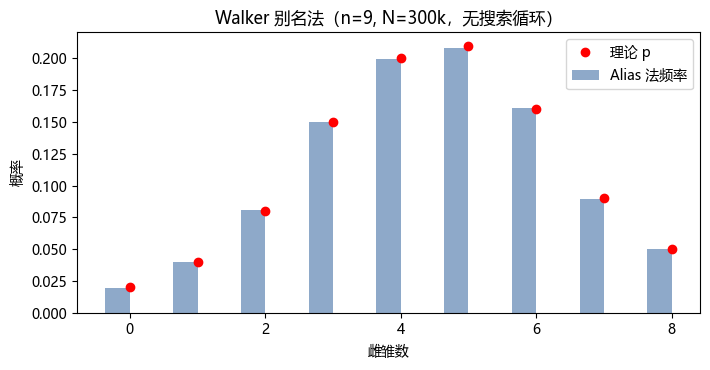

In [4]:
rw = [0.02, 0.04, 0.08, 0.15, 0.2, 0.21, 0.16, 0.09, 0.05]   # S&M Table 2.1
n = len(rw); S = 1.0 / n
tab = list(rw); Q = [0.0] * n; A = [-1] * n                   # A=-1：无别名

def first_under():
    return next(k for k in range(n) if 0 < tab[k] <= S)
def first_over():
    return next(k for k in range(n) if tab[k] >= S)

for _ in range(n - 1):
    t, y = first_under(), first_over()
    Q[t] = tab[t]; tab[t] = 0.0        # 扇区 t 定稿
    A[t] = y                            # 余量记到 y 名下
    tab[y] -= S - Q[t]
t_max = int(np.argmax(tab)); Q[t_max] = tab[t_max]
Q = [q * n for q in Q]                  # 乘 n = 扇区被选中概率 1/n
print("Q =", [round(q, 2) for q in Q])
print("A =", ["-" if a == -1 else a + 1 for a in A], "  （1 基，与原书表逐位一致；- 表示无别名）")

Md = 300_000
u = rng.random(Md)
Y = (u * n).astype(int)                 # 等可能选扇区
Z = u * n - Y                           # 扇区内位置
Qa, Aa = np.array(Q), np.array(A)
Xa = np.where(Z < Qa[Y], Y, Aa[Y])      # Z < Q[Y] 留在本扇区，否则取别名
freq = np.bincount(Xa, minlength=n) / Md
print("最大频率偏差:", float(np.abs(freq - np.array(rw)).max()))

fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.bar(np.arange(n) - 0.18, freq, width=0.36, color="#8ea9c9", label="Alias 法频率")
ax.plot(np.arange(n), rw, "ro", ms=6, label="理论 p")
ax.set(xlabel="雌雏数", ylabel="概率", title=f"Walker 别名法（n={n}, N={Md//1000}k，无搜索循环）")
ax.legend(); fig.tight_layout(); save(fig, "out-4-3.png"); plt.show()

## 实验 4 舍选法：Beta(2,5)（§4.1.4）

目标 $f(x)=30x(1-x)^4$（Beta(2,5)），proposal $g=U(0,1)$，$M=\max f=f(1/5)=2.4576$。判据 $R\cdot M\le f(x)$ 接受。理论接受率 $1/M=0.4069$。

实测接受率 0.4070（理论 1/M = 0.4069）
样本均值 0.2856（理论 2/7 = 0.2857），样本方差 0.02553（理论 10/392 = 0.02551）


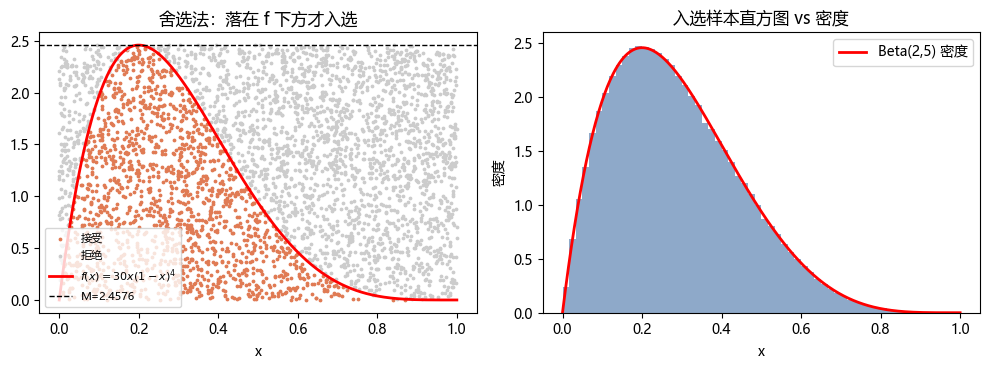

In [5]:
f = lambda x: 30 * x * (1 - x) ** 4     # Beta(2,5) 密度
M = 30 * 0.2 * 0.8 ** 4                 # 2.4576
target, batch = 400_000, 100_000
acc_parts, tried, got = [], 0, 0
while got < target:
    x = rng.random(batch); r = rng.random(batch)
    ok = r * M <= f(x)
    acc_parts.append(x[ok]); tried += batch; got += int(ok.sum())
X = np.concatenate(acc_parts)[:target]
print(f"实测接受率 {got/tried:.4f}（理论 1/M = {1/M:.4f}）")
print(f"样本均值 {X.mean():.4f}（理论 2/7 = {2/7:.4f}），样本方差 {X.var():.5f}（理论 10/392 = {10/392:.5f}）")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
xs, rs = rng.random(4000), rng.random(4000)
ok = rs * M <= f(xs)
ax[0].scatter(xs[ok], rs[ok] * M, s=3, color="#e07b54", label="接受")
ax[0].scatter(xs[~ok], rs[~ok] * M, s=3, color="#cccccc", label="拒绝")
xx = np.linspace(0, 1, 400)
ax[0].plot(xx, f(xx), "r-", lw=2, label=r"$f(x)=30x(1-x)^4$")
ax[0].axhline(M, color="k", ls="--", lw=1, label=f"M={M:.4f}")
ax[0].set(title="舍选法：落在 f 下方才入选", xlabel="x", ylabel="")
ax[0].legend(fontsize=8)
ax[1].hist(X, bins=60, range=(0, 1), density=True, color="#8ea9c9")
ax[1].plot(xx, stats.beta.pdf(xx, 2, 5), "r-", lw=2, label="Beta(2,5) 密度")
ax[1].set(title="入选样本直方图 vs 密度", xlabel="x", ylabel="密度"); ax[1].legend()
fig.tight_layout(); save(fig, "out-4-4.png"); plt.show()

## 实验 5 Box–Muller：正态抽样（§4.1.7）

$X_1=\cos(2\pi U_1)\sqrt{-2\ln U_2}$，$X_2=\sin(2\pi U_1)\sqrt{-2\ln U_2}$ 独立同 $N(0,1)$。左图验证 $(X_1,X_2)$ 圆对称（径向密度 $\propto e^{-r^2/2}$、角度均匀）；KS 检验给正态性一个正式的 p 值。

Z1: 均值 -0.0023（0），方差 0.9944（1），|corr(Z1,Z2)| = 0.0028
KS 检验（Z1 vs N(0,1)）: p = 0.434（> 0.05，通过）


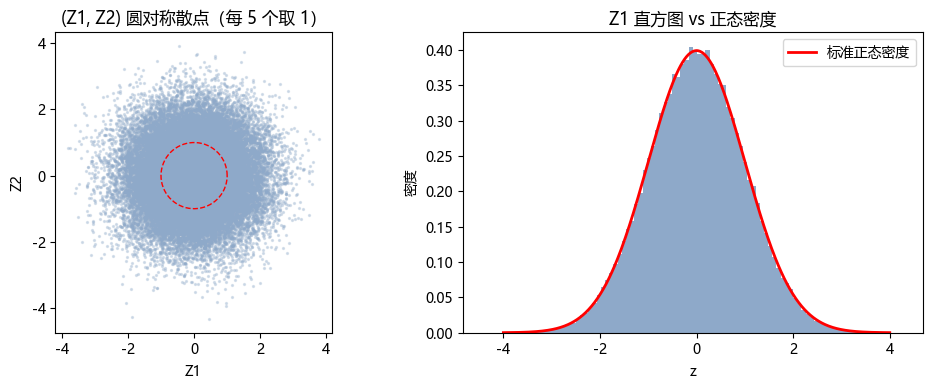

In [6]:
n = 200_000
u1, u2 = rng.random(n), rng.random(n)
R = np.sqrt(-2 * np.log(u2))
Z1, Z2 = R * np.cos(2 * np.pi * u1), R * np.sin(2 * np.pi * u1)
ks_p = stats.kstest(Z1, "norm").pvalue
print(f"Z1: 均值 {Z1.mean():.4f}（0），方差 {Z1.var():.4f}（1），|corr(Z1,Z2)| = {abs(np.corrcoef(Z1, Z2)[0, 1]):.4f}")
print(f"KS 检验（Z1 vs N(0,1)）: p = {ks_p:.3f}（> 0.05，通过）")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(Z1[::5], Z2[::5], s=2, alpha=0.3, color="#8ea9c9")
th = np.linspace(0, 2 * np.pi, 200)
ax[0].plot(np.cos(th), np.sin(th), "r--", lw=1)
ax[0].set(title="(Z1, Z2) 圆对称散点（每 5 个取 1）", aspect="equal", xlabel="Z1", ylabel="Z2")
xx = np.linspace(-4, 4, 400)
ax[1].hist(Z1, bins=100, density=True, color="#8ea9c9")
ax[1].plot(xx, np.exp(-xx**2 / 2) / np.sqrt(2 * np.pi), "r-", lw=2, label="标准正态密度")
ax[1].set(title="Z1 直方图 vs 正态密度", xlabel="z", ylabel="密度"); ax[1].legend()
fig.tight_layout(); save(fig, "out-4-5.png"); plt.show()

## 实验 6 变换法：Cauchy 的厚尾（§4.1.1）

$Y\sim U(-\pi/2,\pi/2)$，$X=\tan Y$ 得柯西样本。它方差不存在——累积均值永远不收敛（打印各累积均值看它乱跳）；尾巴之厚用 $|X|>10$ 的占比衡量：柯西约 6.3%，正态只有 $\sim10^{-23}$。

累积均值的不稳定: N=100: -1.185  N=1000: -5.619  N=10000: +23.320  N=100000: +5.152  N=200000: +4.322
|X|>10 占比 0.0632（柯西理论 0.0635；正态约为 1.5e-23）


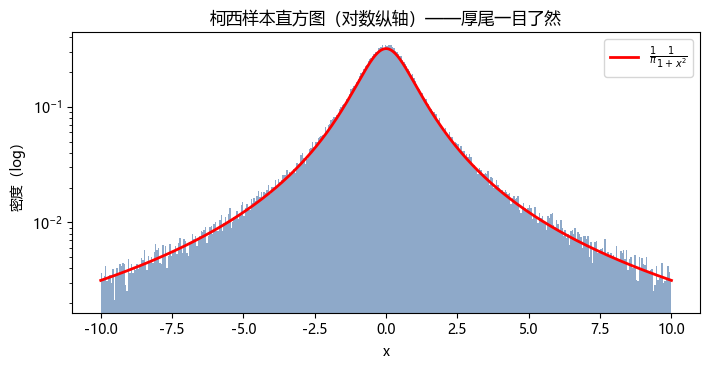

In [7]:
u = rng.random(200_000)
Xc = np.tan(np.pi * (u - 0.5))
print("累积均值的不稳定:", "  ".join(f"N={m}: {Xc[:m].mean():+.3f}" for m in (100, 1_000, 10_000, 100_000, 200_000)))
tail = np.mean(np.abs(Xc) > 10)
print(f"|X|>10 占比 {tail:.4f}（柯西理论 {1 - 2/np.pi*np.arctan(10):.4f}；正态约为 1.5e-23）")

fig, ax = plt.subplots(figsize=(7.2, 3.8))
xx = np.linspace(-10, 10, 800)
ax.hist(Xc, bins=400, range=(-10, 10), density=True, color="#8ea9c9")
ax.plot(xx, stats.cauchy.pdf(xx), "r-", lw=2, label=r"$\frac{1}{\pi}\frac{1}{1+x^2}$")
ax.set(yscale="log", title="柯西样本直方图（对数纵轴）——厚尾一目了然", xlabel="x", ylabel="密度（log）")
ax.legend(); fig.tight_layout(); save(fig, "out-4-6.png"); plt.show()

## 实验 7 组合法：Erlang 卷积与 Gamma 相除得 Beta（§4.1.5）

$k$ 个独立 $Exp(1)$ 之和 $\sim Gamma(k,1)$（再生性质）。把 7 个指数分成前 2 个、后 5 个之和：$G_1\sim Gamma(2,1)$、$G_2\sim Gamma(5,1)$，则 $G_1/(G_1+G_2)\sim Beta(2,5)$——与实验 4 用舍选法抽的是同一条密度，两种完全不同的路线交叉验证。

Erlang(3): 均值 2.9993（理论 3），方差 2.9901（理论 3）
Beta(2,5)（Gamma 相除）: 均值 0.2861（理论 2/7 = 0.2857）


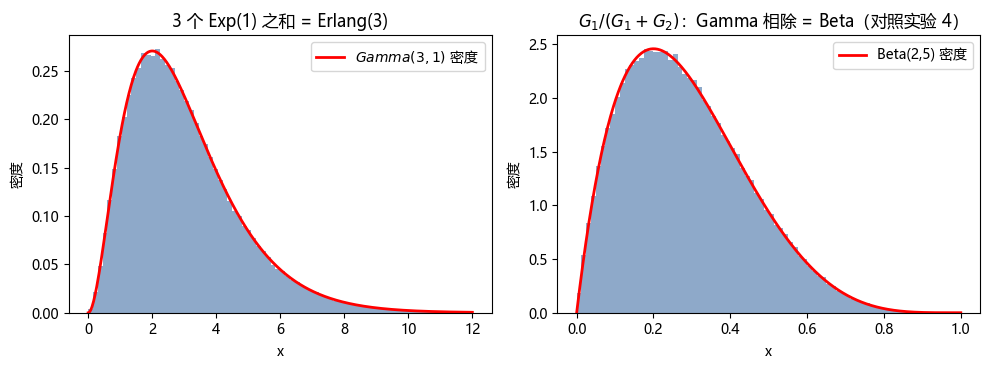

In [8]:
n = 200_000
E = -np.log1p(-rng.random((n, 7)))       # 7 列独立 Exp(1)
G3 = E[:, :3].sum(axis=1)                # Erlang(3)
G1, G2 = E[:, :2].sum(axis=1), E[:, 2:].sum(axis=1)
Xb = G1 / (G1 + G2)                      # Beta(2,5)
print(f"Erlang(3): 均值 {G3.mean():.4f}（理论 3），方差 {G3.var():.4f}（理论 3）")
print(f"Beta(2,5)（Gamma 相除）: 均值 {Xb.mean():.4f}（理论 2/7 = {2/7:.4f}）")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
xx = np.linspace(0, 12, 500)
ax[0].hist(G3, bins=80, range=(0, 12), density=True, color="#8ea9c9")
ax[0].plot(xx, stats.gamma.pdf(xx, 3), "r-", lw=2, label=r"$Gamma(3,1)$ 密度")
ax[0].set(title="3 个 Exp(1) 之和 = Erlang(3)", xlabel="x", ylabel="密度"); ax[0].legend()
xx = np.linspace(0, 1, 500)
ax[1].hist(Xb, bins=80, range=(0, 1), density=True, color="#8ea9c9")
ax[1].plot(xx, stats.beta.pdf(xx, 2, 5), "r-", lw=2, label="Beta(2,5) 密度")
ax[1].set(title=r"$G_1/(G_1+G_2)$：Gamma 相除 = Beta（对照实验 4）", xlabel="x", ylabel="密度")
ax[1].legend()
fig.tight_layout(); save(fig, "out-4-7.png"); plt.show()

## 实验 8 Gibrat 定律：乘积 → 对数正态（§4.1.7）

$R\sim U(0.2,2)$，$X=\prod_{i=1}^{10}R_i$。理论：$\ln X\approx N(\alpha,\beta^2)$，$\alpha=-0.510$、$\beta^2=3.220$（原书数值）。对数纵轴下直方图应贴上 $LN$ 密度。

理论 α = -0.510, β² = 3.220, β = 1.795（原书 -0.510 / 3.220 / 1.794）
模拟 ln X: 均值 -0.509（α），标准差 1.861（β）


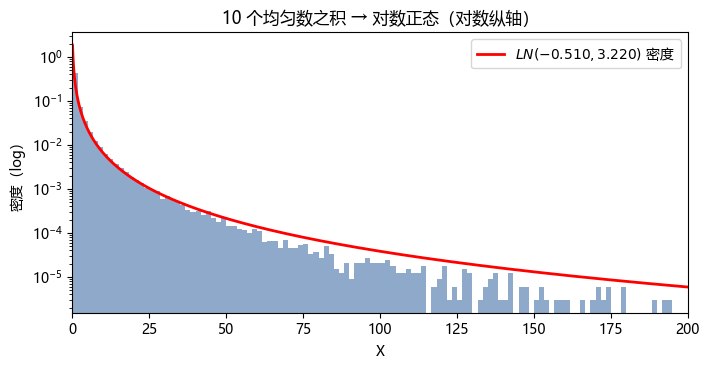

In [9]:
a, b, k, N = 0.2, 2.0, 10, 200_000
c = b - a
X = rng.uniform(a, b, (N, k)).prod(axis=1)
alpha = (k / c) * (b * (np.log(b) - 1) - a * (np.log(a) - 1))
beta2 = (k / c) * (b * (np.log(b)**2 - 2*np.log(b) + 2) - a * (np.log(a)**2 - 2*np.log(a) + 2)) - alpha**2
beta = np.sqrt(beta2)
print(f"理论 α = {alpha:.3f}, β² = {beta2:.3f}, β = {beta:.3f}（原书 -0.510 / 3.220 / 1.794）")
print(f"模拟 ln X: 均值 {np.log(X).mean():.3f}（α），标准差 {np.log(X).std():.3f}（β）")

fig, ax = plt.subplots(figsize=(7.2, 3.8))
xx = np.linspace(0.02, 200, 1000)
ax.hist(X, bins=120, range=(0, 200), density=True, color="#8ea9c9")
ax.plot(xx, np.exp(-(np.log(xx) - alpha)**2 / (2 * beta2)) / (xx * beta * np.sqrt(2 * np.pi)),
        "r-", lw=2, label=r"$LN(-0.510, 3.220)$ 密度")
ax.set(yscale="log", xlim=(0, 200), title="10 个均匀数之积 → 对数正态（对数纵轴）",
       xlabel="X", ylabel="密度（log）")
ax.legend(); fig.tight_layout(); save(fig, "out-4-8.png"); plt.show()

## 实验 9 离散事件模拟：M/M/1 排队（§4.2.4）

事件调度法：维护"下一到达 / 下一离开"两个候补事件，跳到较早者处理。$\lambda=0.9,\mu=1$（$\rho=0.9<1$ 稳态存在），理论 $W_q=9$、$W=10$、$L=\lambda W=9$。单跑 $T=10^5$ 看瞬态，12 次重复取 burn-in（前 500 位顾客丢弃）后平均。

单跑：前 500 人 Wq 均值 12.74（瞬态未消，不进入统计），burn-in 后 9.14


Wq = 9.11 ± 0.34（理论 λ/(μ(μ-λ)) = 9.00）
W  = 10.11 ± 0.34（理论 1/(μ-λ) = 10.00）
Little 定律: L = λW = 9.10（理论 λ/(μ-λ) = 9.00）


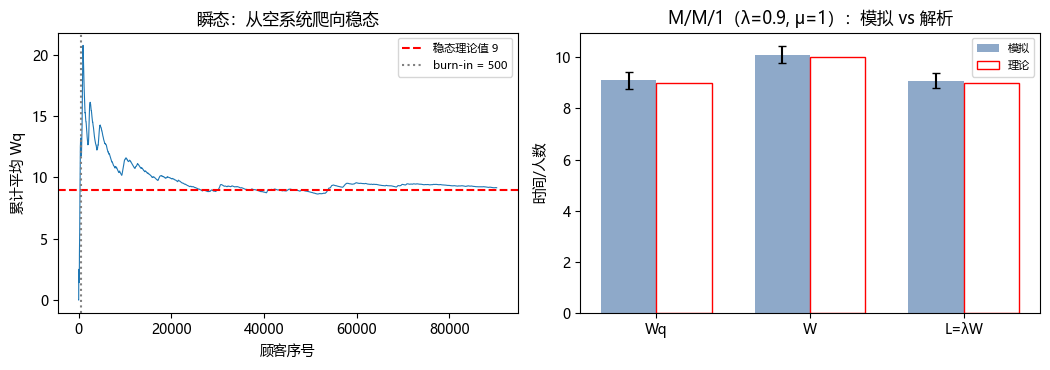

In [10]:
def mm1(lam, mu, T, rng):
    t = 0.0
    next_arr = rng.exponential(1 / lam)
    next_dep = np.inf
    head = None                       # 队头顾客的到达时刻
    queue = deque()
    Wq, W = [], []
    while t < T:
        if next_arr < next_dep:       # —— 到达事件
            t = next_arr
            if head is None:          # 系统空：立即服务
                head = t; Wq.append(0.0)
                next_dep = t + rng.exponential(1 / mu)
            else:
                queue.append(t)
            next_arr = t + rng.exponential(1 / lam)
        else:                         # —— 离开事件
            t = next_dep
            W.append(t - head)        # 逗留 = 离开 - 到达
            if queue:
                head = queue.popleft()
                Wq.append(t - head)   # 排队等待 = 开始服务 - 到达
                next_dep = t + rng.exponential(1 / mu)
            else:
                head = None; next_dep = np.inf
    return np.array(Wq), np.array(W)

lam, mu = 0.9, 1.0
Wq1, W1 = mm1(lam, mu, 100_000, rng)          # 单条长跑看瞬态
burn = 500
print(f"单跑：前 {burn} 人 Wq 均值 {Wq1[:burn].mean():.2f}（瞬态未消，不进入统计），burn-in 后 {Wq1[burn:].mean():.2f}")

reps = 12
Wq_r, W_r = np.empty(reps), np.empty(reps)
for r in range(reps):
    wq, w = mm1(lam, mu, 20_000, rng)
    Wq_r[r], W_r[r] = wq[burn:].mean(), w[burn:].mean()
se = lambda v: v.std(ddof=1) / np.sqrt(reps)
print(f"Wq = {Wq_r.mean():.2f} ± {se(Wq_r):.2f}（理论 λ/(μ(μ-λ)) = 9.00）")
print(f"W  = {W_r.mean():.2f} ± {se(W_r):.2f}（理论 1/(μ-λ) = 10.00）")
print(f"Little 定律: L = λW = {lam * W_r.mean():.2f}（理论 λ/(μ-λ) = 9.00）")

fig, ax = plt.subplots(1, 2, figsize=(10.6, 3.8))
run = np.cumsum(Wq1) / np.arange(1, len(Wq1) + 1)
ax[0].plot(run, lw=0.8)
ax[0].axhline(9, color="r", ls="--", lw=1.5, label="稳态理论值 9")
ax[0].axvline(burn, color="gray", ls=":", lw=1.5, label=f"burn-in = {burn}")
ax[0].set(xlabel="顾客序号", ylabel="累计平均 Wq", title="瞬态：从空系统爬向稳态")
ax[0].legend(fontsize=8)
labels = ["Wq", "W", "L=λW"]
sim = [Wq_r.mean(), W_r.mean(), lam * W_r.mean()]
err = [se(Wq_r), se(W_r), lam * se(W_r)]
theo = [9, 10, 9]
xp = np.arange(3)
ax[1].bar(xp - 0.18, sim, width=0.36, yerr=err, capsize=3, color="#8ea9c9", label="模拟")
ax[1].bar(xp + 0.18, theo, width=0.36, color="none", edgecolor="r", label="理论")
ax[1].set_xticks(xp); ax[1].set_xticklabels(labels)
ax[1].set(title="M/M/1（λ=0.9, μ=1）：模拟 vs 解析", ylabel="时间/人数")
ax[1].legend(fontsize=8)
fig.tight_layout(); save(fig, "out-4-9.png"); plt.show()